In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Due to a Jupyter bug, the %matplotlib inline "magic" command needs to be in 
# its own cell. See:
# https://github.com/jupyter/notebook/issues/3385

%matplotlib inline

In [3]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 16}
matplotlib.rc('font', **font)
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['figure.dpi'] = 150
matplotlib.rcParams['figure.figsize'] = [5, 3.5]
matplotlib.rcParams["text.usetex"] = False
matplotlib.rcParams["font.family"]="serif"

In [4]:
from scipy.stats import lognorm

class sample(object):
    
    def __init__(self, lnscale=1., 
                 lns=0.3, 
                 fluxlim_nominal = 1./4./np.pi/0.5/0.5, 
                 fluxlim_scatter=0.3, 
                 rmax=1., N=100000):
        
        rmax = 1.
        self.r = (np.random.rand(N))**(1./3.)*rmax
        lum_func = lognorm(s=lns, scale=lnscale)
        self.lum = lum_func.rvs(N)
        self.lum2 = lum_func.rvs(N)
        self.flux = self.lum/4/np.pi/self.r/self.r
        if fluxlim_nominal is not None:
            self.fluxlim = lognorm(scale=fluxlim_nominal, s=fluxlim_scatter).rvs(N)
            self.sel = self.flux > self.fluxlim
        else:
            self.sel = np.ones_like(self.flux)
        self.lums = self.lum[self.sel]
        self.rs = self.r[self.sel]
            
    def hist(self, q, qlabel, sel=True, mean=True, **kwargs):
        if sel:
            x = q[self.sel]
        else:
            x = q
        plt.hist(x, **kwargs)
        plt.ylabel(r"$N$")
        plt.xlabel(qlabel)
        if mean:
            mn = np.mean(x)
            plt.axvline(mn,label='mean: {:5.3f}\n std:{:5.3f}'.format(mn, np.std(x)))
            plt.legend()        
            
    def hist_r(self, sel=True, mean=True, **kwargs):
        self.hist(self.r, r"$r$", sel, mean, **kwargs)

    def hist_loglum(self, sel=True, mean=True, **kwargs):
        self.hist(np.log(self.lum), r"$\log L$", sel, mean, **kwargs)    
        
    def hist_mag(self, sel=True, mean=True, **kwargs):
        self.hist(-2.5*np.log10(self.lum), "mag", sel, mean, **kwargs)
        
    def hist_lum(self, sel=True, mean=True, **kwargs):
        self.hist(self.lum, r"$L$", sel, mean, **kwargs)
    
    def hist_lum2(self, sel=True, mean=True, **kwargs):
        self.hist(self.lum2, r"$L$", sel, mean, **kwargs)

    def hist_flux(self, sel=True, mean=True, **kwargs):
        self.hist(self.flux, r"$f$", sel, mean, **kwargs)
        
    def hist_fluxlim(self, sel=True, mean=True, **kwargs):
        self.hist(self.fluxlim, r"$f_{lim}$",sel, mean, **kwargs)

    def scatter(self, sel=True, thin=True, *args, **kwargs):
        if thin:
            x = self.r[::50]
            y = self.lum[::50]
            selt = self.sel[::50]
        else:
            x = self.r
            y = self.lum
            selt = self.sel
        if sel:
            x = x[selt]
            y = y[selt]

        plt.scatter(x, y, *args, **kwargs)
        plt.xlabel(r'$r$')
        plt.ylabel(r'$L$')    
        
    def scatter2(self, sel=True, thin=True, *args, **kwargs):
        if thin:
            x = self.lum[::20]
            y = self.lum2[::20]
            selt = self.sel[::20]
        else:
            x = self.lum
            y = self.lum2
            selt = self.sel
        if sel:
            x = x[selt]
            y = y[selt]

        plt.scatter(x, y, *args, **kwargs)
        plt.xlabel(r'$L$')
        plt.ylabel(r'$L_2$')

# Selection Effects in Astronomy

Q: How significant is the correlation below?

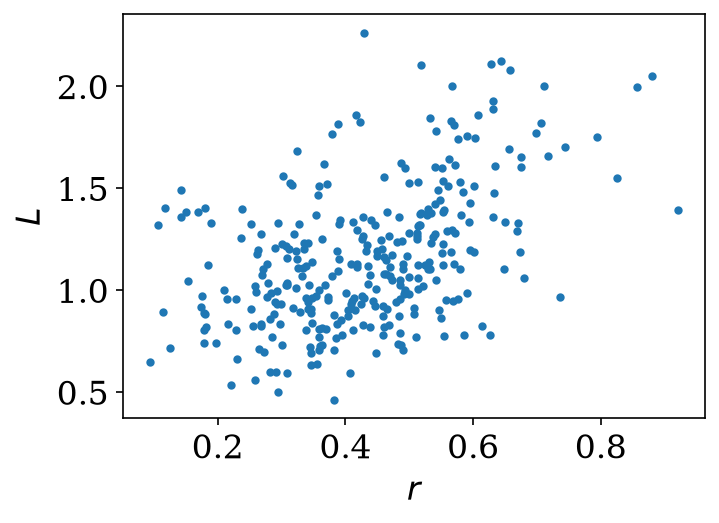

In [5]:
samp=sample(lns=0.3)
samp.scatter(marker=".")

In [6]:
from scipy.stats import pearsonr
(r,p) = pearsonr(samp.rs, samp.lums)
print("Pearson r: {:5.3f}, prob (under null hypothesis of no corr): {:8.6f}"
      .format(r,p))

Pearson r: 0.427, prob (under null hypothesis of no corr): 0.000000


A: There is really _no_ correlation. 

**Beware** of plotting **distance-dependent** quantities against each other, when there are selection effects.

Pearson r: -0.003, prob (under null hypothesis of no corr): 0.372488


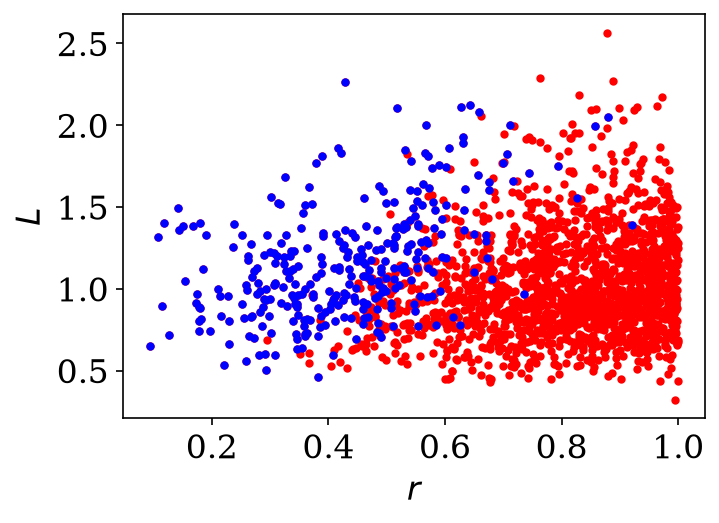

In [7]:
samp.scatter(sel=False, marker=".", color='r')
samp.scatter(sel=True, marker=".", color='b')
(r,p) = pearsonr(samp.r, samp.lum) # Whole sample
print("Pearson r: {:5.3f}, prob (under null hypothesis of no corr): {:8.6f}"
      .format(r,p))

The true distribution of log(luminosities)

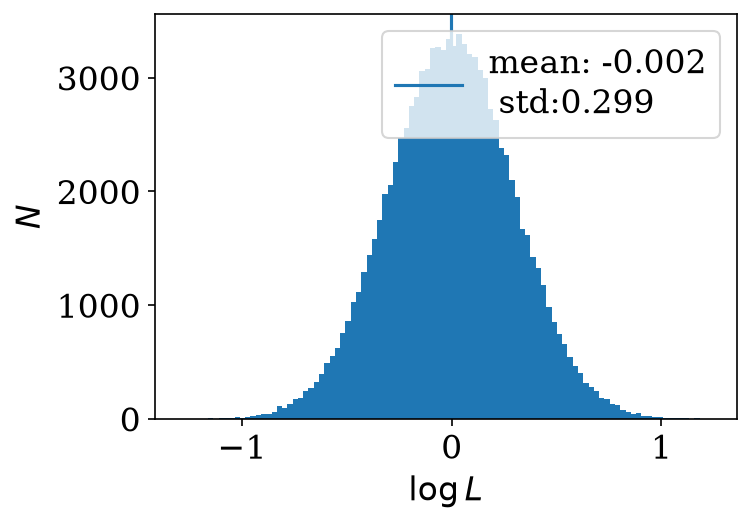

In [8]:
samp.hist_loglum(sel=False, bins=100)

The _selected_ distribution of log(luminosities)

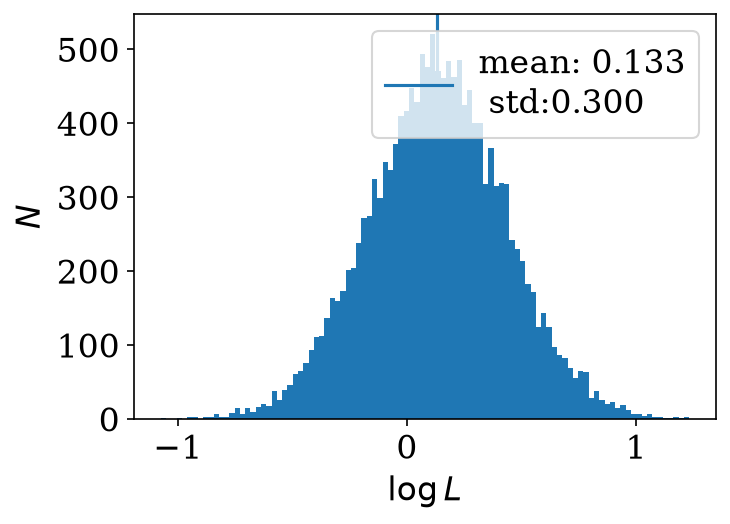

In [9]:
samp.hist_loglum(bins=100)

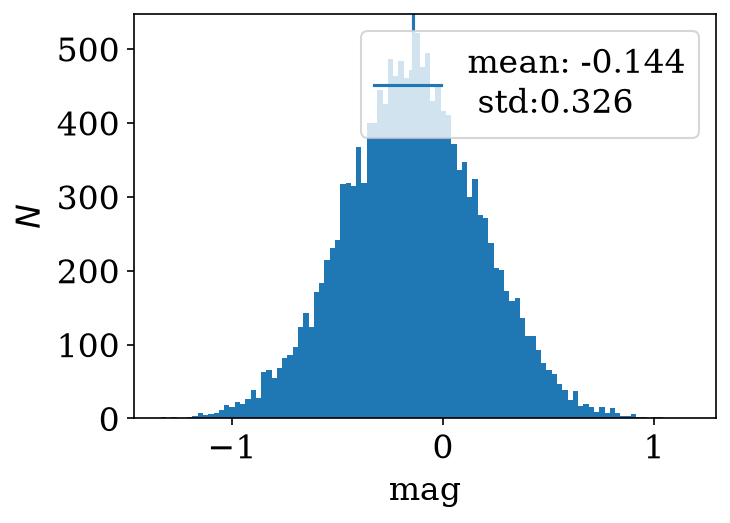

In [10]:
samp.hist_mag(bins=100)

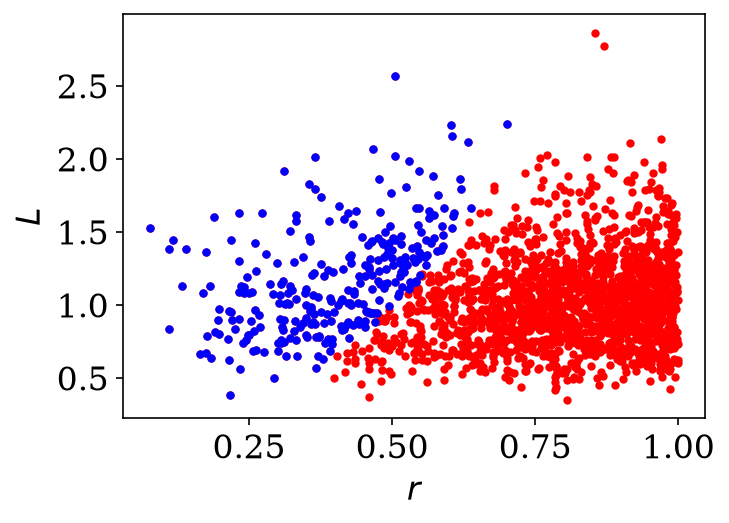

In [11]:
samp2=sample(fluxlim_scatter=0.01)

samp2.scatter(sel=False, marker=".", color='r')
samp2.scatter(sel=True, marker=".", color='b')

The bias does not depend on the details of the magnitude limit:

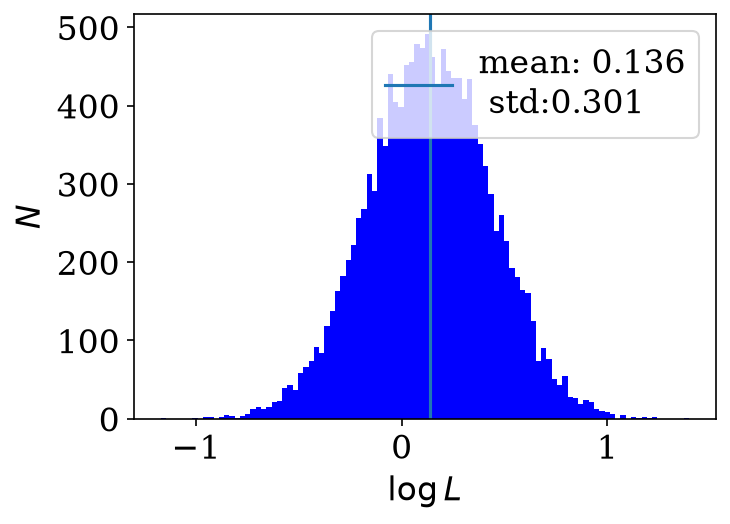

In [12]:
samp2.hist_loglum(bins=100, color='b')
#samp2.hist_loglum(sel=False, bins=100, color='r')

## (Eddington-)Malmquist bias

This bias was first computed by Eddington (1914), but usually goes by the name Malmquist bias.

It is a bias in the luminosity (or distances) of a flux-limited sample, compared to  what one could observe if there were no flux limit.

Notice that the bias does not actually depend on value of the flux limit, only that it is _flux-limited_.

If 
$$
p_{\rm prior}(r)dr \propto r^2 dr
$$

It's easier to do everything with natural logs, let $l = \ln(r)$, so that $e^l = r$.

Now using the transformation of probabilities we get 
$$
p_{\rm prior}(l)dl \propto e^{3l}dl
$$

Now suppose we have an object of known flux $f$.

$$
f = \frac{L}{4\pi r^2}
$$
taking $\ln$ 
$$
\begin{eqnarray}
\ln f & = & \ln L - \ln(4\pi) - 2\ln(r)\\
      & = & \ln L - \ln(4\pi) - 2l
\end{eqnarray}
$$
so
$$
l = \frac{\ln L - \ln(4\pi f)}{2}
$$

Finally, let's suppose that the probability of $\ln L$ is described by a normal distribution ${\cal N}(\overline{\ln L}, \sigma_{\ln L})$. 
Then defining
$$
\overline{l} = \frac{\overline{\ln L}-\ln f-\ln(4\pi)}{2}
$$
we get
$$
p(l|f) =  {\cal N}\left(\overline{l}, \frac{\sigma_{\ln L}}{2}\right)
$$

But to get the total probabilty for a flux-limited sample, we must multiply by the prior $p(l) \propto e^{3l}$. This is just the mathematical way of saying that, because there is more volume at greater distances, it is more likely that the galaxy is overluminous than underluminous.

$$
p(l|f) \propto {\cal N}\left(\overline{l}, \frac{\sigma_{\ln L}}{2}\right) e^{3l}
$$

Since the normal distribution is also an exponential we can combine all terms in the numerator, complete the square and we see that the mean has shifted. This is the Malmquist bias effect. 

$$
p(l|f) = {\cal N}(\overline{l}+3\left(\frac{\sigma_{\ln L}}{2}\right)^2, \sigma_{\ln L}/2)
$$

Note that, for this case, the bias does NOT depend on the value of the flux, $f$, or the mean luminosity, only on the scatter in the log luminosity (or log distance) ....

The shift in $\ln L$ is double that in $l$

$$
p(\ln L) = {\cal N}(\overline{\ln L}+\frac{3}{2}(\sigma_{\ln L})^2, \sigma_{\ln L})
$$

For $\sigma_{\ln L} = 0.3$, the above formula gives: 0.135

Finally since $\ln L = -0.4\ln(10)M + K = -0.921 M + K$, then $\sigma_{\ln L} = 0.921 \sigma_M$, the shift in mags is:

$$
p(M) = {\cal N}(\overline{M}-1.38(\sigma_{M})^2, \sigma_{M})
$$

This is Eddington's original 1914 formula.

More generally, if the intrinsic luminosity distribution is $\phi(L)$ and the volume of the Universe in which an object of luminosity $L$ is bright enough to be included in the sample is $V(L)$ then the observed number 

$$
n(L) \propto \phi(L) V(L)
$$

## Estimating the luminosity function

Two ways:

* Vmax
* Maximum-likelihood

### Vmax

The Vmax method is simple: one simply weights the observed distribution $n(L)$ by dividing by the maximum volume $V_{\mathrm{max}}(L)$ out to which you could have observed the data.

The disadvantage of this method is that it assumes the data are homogeneously distributed within the volume.

### Maximum-Likelihood

If the probability of a galaxy having a luminosity $L$ and position $\mathbf{r}$ are _independent_ then 

$$
p(L, r) = \phi(L) \, n(\mathbf{r})
$$

Now the objects in a sample are subject to a selection effect $S(f)$, where $f = L/(4\pi r^2)$. Then the *joint* probability distribution of $L$ and $r$ for the selected sample is:

$$
p_S(L,r) \propto S(f[L, r])\, \phi(L) \, n(r)
$$

$$
\begin{eqnarray}
p_S(L|r) & = & \frac{p_S(L,r)}{p_S(r)} \\
        & = &  \frac{S(f[L,r]) \, \phi(L) \, n(r)}{\int_0^{\infty} S(f[L,r])\, \phi(L) \, n(r) dL} \\
        & = & \frac{S(f[L,r]) \,\phi(L)}{\int_0^{\infty} S(f[L,r]) \, \phi(L) dL}
\end{eqnarray}
$$
Notice that $n(r)$ drops out!

If there is a well-defined flux (apparent magnitude) limit then $S(f)$ is just a step function:

$S = 0$ for $f<f_{lim}$ and 1 for $f>f_{lim}$.

Define $L_{lim}(r) = f_{lim}(4\pi r^2)$.

We get

$$
p_S(L|r) = \frac{\phi(L)}{\int_{L_{lim}(r)}^{\infty} \phi(L) dL}
$$

We can then maximise the likelihood of the entire observed sample

$$
\ln {\cal L} = \sum_i \ln p_S(L_i|r_i)
$$

as a function of the parameters of the luminosity function $\phi(L)$. 

## Eddington (1913) bias


A related problem occurs when data has observational (measurement) errors.

Suppose that these are fluxes. Then a catalogue of observed (raw) fluxes will have a different distribution as a function of flux, compared with the ideal no-measurement-error ("intrinsic") version.

In general, the measurement error _convolves_ the underlying intrinsic distribution of the parameter. 

If the observed distribution is $o(x)$ and the intrisic distribution is $i(x)$ then
$$
o(x) = i(x) \star e(x) = \int_{-\infty}^{\infty} i(x') e(x-x') d x'
$$

If the underlying distribution is flat (at least over the scale of the measurement error) there is no effect.

But if the slope is steep, then the effect becomes larger.

The effect can be modelled locally as a horizontal shift.

If the error distribution is Gaussian, $e(x-x') = {\cal N}(0, \sigma)$, and $\sigma$ is small compared to variations in $i$, then the intrinsic distribution can be obtained from the observed one: 
$i(x-\Delta x) \sim o(x)$ where 

$$
\Delta x = -\sigma^2 \frac{1}{o(x)} \frac{d o(x)}{dx}
$$

The bias can also be modelled as a vertical shift. For one common case, stellar mass functions in the presence of uncertainties in the stellar-masses

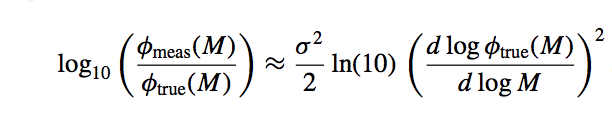

where $\sigma$ is the error in $\log(M_*)$ (from Behroozi, Conroy and Wechsler [2010])

The bias goes away as the measurement error $\sigma \rightarrow 0$ or as the slope of the mass function goes to zero. 

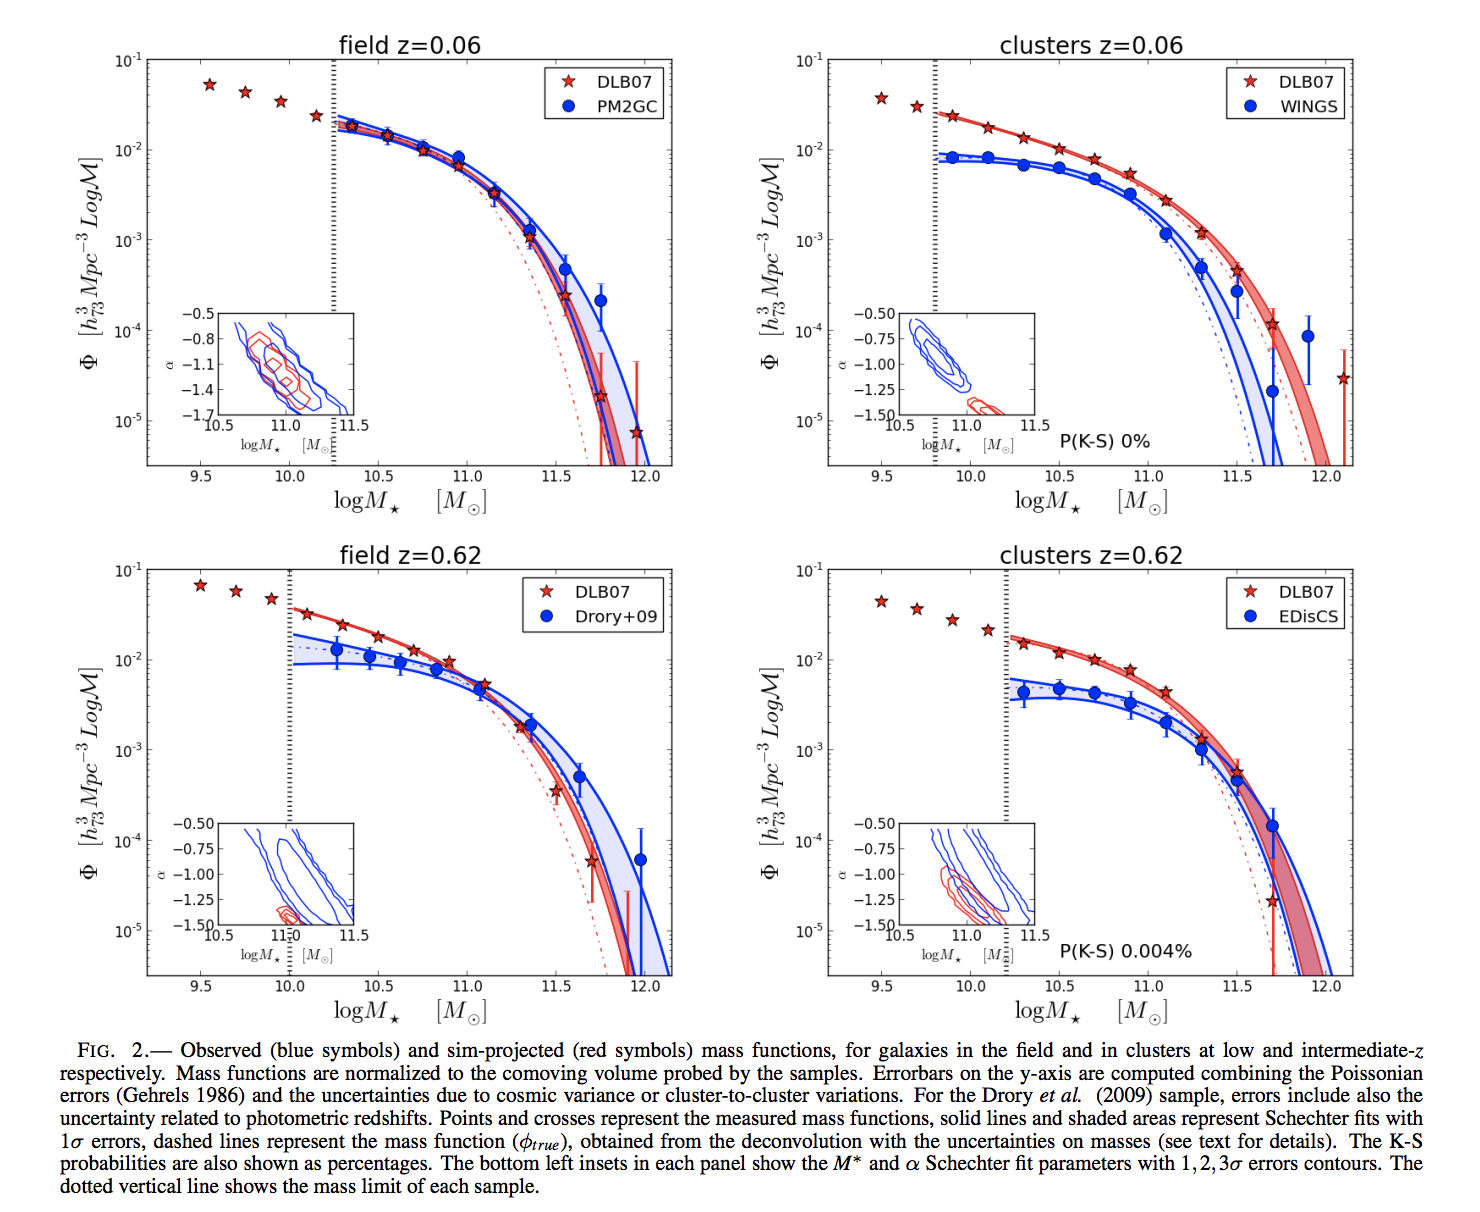

There are two approaches: 
    
1. **Direct deconvolution**. A weakness of this method is that noise is amplified.

2. **Forward modeling** the convolution: the probability of the observed data is given by a model for the intrinsic distribution which is then convolved with the observational uncertainties. A weakness here is that usually one needs to assume a parametric model for the intrinsic distribution.
   